# Лабораторная работа № 1
## Инструментальные средства подготовки датасета для интеллектуального анализа данных
**BANKFLOW · ДГТУ · ВОЗПИ-31**

Цель: исследовать структуру набора данных, применить Python для первичного анализа, визуализации и очистки. Учебный датасет обращений вымышленного банковского подразделения; согласование выбора и уникальности с преподавателем ещё требуется. Блокнот выполнен локальным ядром Jupyter/Python. Для Google Colab загрузите `requests_raw.csv` в рабочую папку и выполните все ячейки. Прогнозирование в данной работе не выполняется.

### 1. Описание набора данных (п. 2.1)
Данные представляют собой синтетическую таблицу обращений: каждое наблюдение — одно обращение. Практические задачи: исследование нагрузки, длительности обработки и распределения по категориям. В дальнейшем можно проверить гипотезы о длительности и разработать модель классификации обращения или регрессии времени, но для модели потребуются отдельные проверки качества и целевого признака.

| Признак | Тип / роль | Назначение |
|---|---|---|
| id | int, идентификатор | уникальный номер обращения |
| client_id | int, ключ | ссылка на условного клиента |
| employee_id | int, ключ | ссылка на исполнителя |
| product_id | int, ключ | ссылка на продукт |
| category | строка, категория | группа продуктов |
| date | строка ISO, дата | день регистрации |
| hours | float, количественный | длительность обработки, ч |
| status | строка, категория | состояние обращения |
| priority | строка, категория | приоритет |

Среднее значение идентификаторов математически вычислимо, но не имеет предметного смысла. Анализируем длительность и частоты категорий.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Локальный репозиторий, Colab или ZIP для преподавателя.
candidates = [Path('requests_raw.csv'), Path('data/requests_raw.csv'),
              Path('../../data/requests_raw.csv')]
source = next((p for p in candidates if p.is_file()), None)
if source is None:
    raise FileNotFoundError('Загрузите requests_raw.csv в рабочую папку Colab')
raw = pd.read_csv(source)
print('Размер:', raw.shape)
display(raw.head(5))

Размер: (361, 9)


,id,client_id,employee_id,product_id,category,date,hours,status,priority
0,1,1,1,1,Карты,2026-06-01,1.0,Закрыто,Высокий
1,2,2,8,4,Инвестиции,2026-06-02,5.5,Закрыто,Обычный
2,3,3,15,7,Вклады,2026-06-03,18.0,Закрыто,Обычный
3,4,4,7,10,Цифровые сервисы,2026-06-04,30.9,В работе,Обычный
4,5,5,14,13,Кредиты,2026-06-05,NaN,Новое,Высокий


### 2. Первичный анализ (п. 2.2)
Проверяем типы, пропуски, число повторов, диапазон длительности, частоты. Отдельно отмечаем признаки с аномальными значениями.

In [2]:
print('Типы и пропуски:')
display(pd.DataFrame({'тип': raw.dtypes.astype(str), 'пропуски': raw.isna().sum()}))
print('Повторяющихся строк:', int(raw.duplicated().sum()))
print('Разные категории:', raw['category'].unique().tolist())
print('Описательная статистика длительности (ч):')
display(raw['hours'].describe().to_frame().T.round(3))
print('Наблюдения с некорректным временем:')
display(raw.loc[raw['hours'].notna() & ~raw['hours'].between(0,72), ['id','category','hours']])

Типы и пропуски:


,тип,пропуски
id,int64,0
client_id,int64,0
employee_id,int64,0
product_id,int64,0
category,object,0
date,object,0
hours,float64,1
status,object,0
priority,object,0


Повторяющихся строк: 1
Разные категории: ['Карты', 'Инвестиции', 'Вклады', 'Цифровые сервисы', 'Кредиты', ' карты ']
Описательная статистика длительности (ч):


,count,mean,std,min,25%,50%,75%,max
hours,360.0,22.768,15.197,-4.0,10.875,21.65,33.725,180.0


Наблюдения с некорректным временем:


,id,category,hours
17,18,Кредиты,-4.0
28,29,Карты,180.0


По исходным данным: 361 запись, 9 полей, один пропуск времени и один точный дубликат. Минимум −4 и максимум 180 часов нарушают выбранное учебное правило 0–72 ч; есть отдельная категория с лишними пробелами. Это признаки дефектов данных, а не свойства реального банковского процесса. Категории различаются по среднему времени, но сами по себе не позволяют сделать причинный вывод.

### 3. Очистка (п. 3)
Удаляем точный повтор. Нормализуем категории. Некорректные длительности заменяем на пропуск; затем заполняем исходный и полученные пропуски медианой допустимых значений. Строки с такими длительностями сохраняются, но ошибочные значения удалены из расчётов. Также проверяем буквальное удаление строк с выбросами (358 строк). Основной набор BANKFLOW сохраняет 360 обращений, а ошибочные значения удаляются из расчётов до заполнения медианой.

In [3]:
df = raw.drop_duplicates().copy()
df['category'] = df['category'].str.strip().str.capitalize()
invalid = df['hours'].notna() & ~df['hours'].between(0,72)
print('Некорректных значений:', int(invalid.sum()))
# Альтернатива: удалить наблюдения с выбросами, а пропуск заполнить медианой.
strict = df.loc[~invalid].copy()
strict['hours'] = strict['hours'].fillna(strict['hours'].median())
print('При удалении строк с выбросами:', strict.shape)
df.loc[invalid, 'hours'] = float('nan')
median = df['hours'].median()
df['hours'] = df['hours'].fillna(median)
print('Медиана для заполнения:', median)
assert df['id'].is_unique
assert df['hours'].between(0,72).all()
assert df['hours'].notna().all()
assert pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce').notna().all()
print('До / после:', raw.shape, '→', df.shape)
display(df.groupby('category')['hours'].agg(['count','mean','min','max']).round(2))
print('Пропусков после очистки:', int(df.isna().sum().sum()))

Некорректных значений: 2
При удалении строк с выбросами: (358, 9)
Медиана для заполнения: 21.6
До / после: (361, 9) → (360, 9)


,count,mean,min,max
category,,,,
Вклады,72,19.37,0.5,44.8
Инвестиции,72,24.04,0.7,44.6
Карты,73,22.02,1.0,43.6
Кредиты,71,24.36,2.0,42.1
Цифровые сервисы,72,22.12,1.0,44.9


Пропусков после очистки: 0


### 4. Визуализация (п. 2.3)
Гистограмма показывает распределение длительности; столбчатая диаграмма — различия между категориями; третий график — сопоставление статусов. Это несколько представлений очищенных данных. Для оценки влияния признаков потребовался бы отдельный анализ.

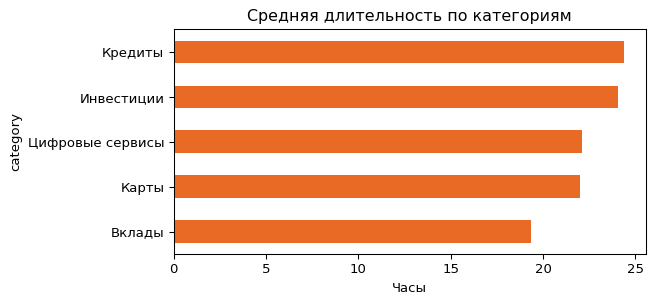

In [4]:
# Графики имеют сохранённые результаты выполнения, а не заглушки.
fig, ax = plt.subplots(figsize=(7,3.3), dpi=95)
df.groupby('category')['hours'].mean().sort_values().plot.barh(ax=ax,color='#e86a24')
ax.set_xlabel('Часы'); ax.set_title('Средняя длительность по категориям')
fig.tight_layout(); plt.show()

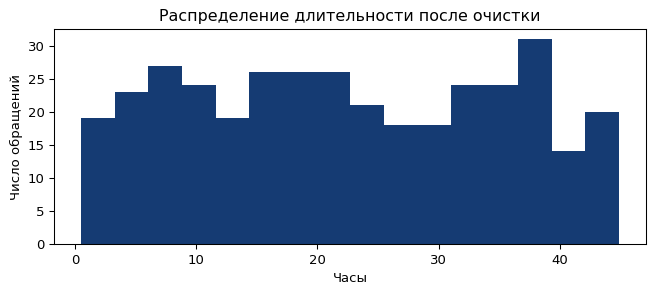

In [5]:
fig, ax = plt.subplots(figsize=(7,3.2), dpi=95)
df['hours'].plot.hist(bins=16, ax=ax,color='#153b73')
ax.set_xlabel('Часы'); ax.set_ylabel('Число обращений')
ax.set_title('Распределение длительности после очистки')
fig.tight_layout(); plt.show()

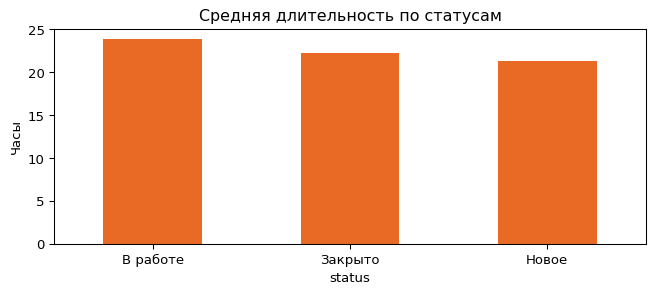

Сохранён очищенный CSV: (360, 9)


In [6]:
fig, ax = plt.subplots(figsize=(7,3.2), dpi=95)
df.groupby('status')['hours'].mean().plot.bar(ax=ax,color='#e86a24',rot=0)
ax.set_ylabel('Часы'); ax.set_title('Средняя длительность по статусам')
fig.tight_layout(); plt.show()
df.to_csv('requests_clean.csv', index=False)
print('Сохранён очищенный CSV:', df.shape)

## Контрольные вопросы
1. Рабочее место специалиста Data Science: Python, Jupyter/Colab, редактор кода, библиотеки анализа/визуализации, система управления версиями и средства загрузки данных.
2. pandas — табличные структуры и операции над ними; NumPy — массивы и численные вычисления; matplotlib — визуализация; scikit-learn — алгоритмы машинного обучения и оценка моделей.
3. Python распространён благодаря доступному синтаксису, развитой библиотечной экосистеме, воспроизводимым блокнотам и интеграциям.

## Вывод
Проверены типы и качество исходных данных; получено 360 уникальных обращений без пропусков, с допустимой длительностью. Графики характеризуют только вымышленный набор данных. Следующий шаг перед сдачей — согласовать датасет и повторить выполнение в Google Colab, если это требуется преподавателем.

Источник: учебный Notebook «ЛР1_Интел_системы_и_технологии_2025.ipynb», раздел «Индивидуальное задание» (опубликован в группе 05.09.2026).